In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [12]:
#read in data and check validity
evals_df = pd.read_excel('../../data/CBDI3 All Evals for NSS.xlsx')
evals_df.head

<bound method NDFrame.head of       Child ID Gender Date of Birth Location - Sub Level 1 contract number  \
0        44879      F    2022-09-27              Southwest      contract 3   
1        47795      F    2020-12-23      Greater Nashville      contract 2   
2        54340      M    2021-06-22        First Tennessee      contract 1   
3        54344      F    2022-03-07    Southeast Tennessee      contract 1   
4        54515      M    2021-11-04          Memphis Delta      contract 3   
...        ...    ...           ...                    ...             ...   
23942  SP03287      F    2023-09-25          Memphis Delta      contract 3   
23943  SP03288      F    2021-05-18          South Central      contract 2   
23944  SP03289      F    2021-10-31          South Central      contract 2   
23945  SP03290      M    2020-03-25          Memphis Delta      contract 3   
23946  SP03291      M    2023-09-18      Greater Nashville      contract 2   

                      Program Lab

In [13]:
#dataframe test
evals_df


,Child ID,Gender,Date of Birth,Location - Sub Level 1,contract number,Program Label,Adaptive Sum of Scaled Scores,Adaptive Developmental Quotient,Adaptive Percentile Rank,Adaptive 95% Confidence Interval,...,Code 1,Code 2,Code 3,Code 4,Code 5,Code 6,Code 7,Code 8,Code 9,Code 10
0,44879,F,2022-09-27,Southwest,contract 3,BDI-3 Eligibility Evaluation,7.0,85.0,16,77-97,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,47795,F,2020-12-23,Greater Nashville,contract 2,BDI-3 Eligibility Evaluation,16.0,88.0,21,82-96,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,54340,M,2021-06-22,First Tennessee,contract 1,BDI-3 Eligibility Evaluation,8.0,90.0,25,81-101,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,54344,F,2022-03-07,Southeast Tennessee,contract 1,BDI-3 Eligibility Evaluation,13.0,115.0,84,103-123,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,54515,M,2021-11-04,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,5.0,75.0,5,68-88,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23942,SP03287,F,2023-09-25,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,13.0,115.0,84,103-123,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23943,SP03288,F,2021-05-18,South Central,contract 2,BDI-3 Eligibility Evaluation,25.0,115.0,84,107-121,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23944,SP03289,F,2021-10-31,South Central,contract 2,BDI-3 Eligibility Evaluation,21.0,103.0,58,96-110,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23945,SP03290,M,2020-03-25,Memphis Delta,contract 3,BDI-3 Annual Evaluation,16.0,88.0,21,82-96,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
#dropping code columns to start cleaning data
evals_df=evals_df.drop(columns=['Code 1','Code 2','Code 3','Code 4','Code 5','Code 6','Code 7','Code 8','Code 9','Code 10'])
evals_df

,Child ID,Gender,Date of Birth,Location - Sub Level 1,contract number,Program Label,Adaptive Sum of Scaled Scores,Adaptive Developmental Quotient,Adaptive Percentile Rank,Adaptive 95% Confidence Interval,...,Cognitive-Perception and Concepts RS,Cognitive-Perception and Concepts SS,Cognitive-Perception and Concepts PR,Cognitive-Perception and Concepts AE,Cognitive-Perception and Concepts RDI,Cognitive-Perception and Concepts CSS,Cognitive-Perception and Concepts CSS 90%,Cognitive-Perception and Concepts Z-Score,Cognitive-Perception and Concepts T-Score,Cognitive-Perception and Concepts NCE
0,44879,F,2022-09-27,Southwest,contract 3,BDI-3 Eligibility Evaluation,7.0,85.0,16,77-97,...,9.0,13.0,84,12,98/90,411.0,392 - 431,1,60.0,71
1,47795,F,2020-12-23,Greater Nashville,contract 2,BDI-3 Eligibility Evaluation,16.0,88.0,21,82-96,...,11.0,7.0,16,18,29/90,437.0,421 - 453,– 1.00,40.0,29
2,54340,M,2021-06-22,First Tennessee,contract 1,BDI-3 Eligibility Evaluation,8.0,90.0,25,81-101,...,10.0,7.0,16,15,37/90,426.0,408 - 444,– 1.00,40.0,29
3,54344,F,2022-03-07,Southeast Tennessee,contract 1,BDI-3 Eligibility Evaluation,13.0,115.0,84,103-123,...,9.0,10.0,50,12,92/90,411.0,392 - 431,0,50.0,50
4,54515,M,2021-11-04,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,5.0,75.0,5,68-88,...,10.0,10.0,50,15,88/90,426.0,408 - 444,0,50.0,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23942,SP03287,F,2023-09-25,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,13.0,115.0,84,103-123,...,6.0,15.0,95,6,>99/90,378.0,365 - 391,1.67,67.0,85
23943,SP03288,F,2021-05-18,South Central,contract 2,BDI-3 Eligibility Evaluation,25.0,115.0,84,107-121,...,20.0,14.0,91,37,99/90,499.0,491 - 508,1.33,63.0,78
23944,SP03289,F,2021-10-31,South Central,contract 2,BDI-3 Eligibility Evaluation,21.0,103.0,58,96-110,...,13.0,10.0,50,25,89/90,464.0,450 - 479,0,50.0,50
23945,SP03290,M,2020-03-25,Memphis Delta,contract 3,BDI-3 Annual Evaluation,16.0,88.0,21,82-96,...,23.0,9.0,37,40,75/90,507.0,500 - 515,– 0.33,47.0,43


In [15]:
#column Check
evals_df.columns.tolist()


['Child ID',
 'Gender',
 'Date of Birth',
 'Location - Sub Level 1',
 'contract number',
 'Program Label',
 'Adaptive Sum of Scaled Scores',
 'Adaptive Developmental Quotient',
 'Adaptive Percentile Rank',
 'Adaptive 95% Confidence Interval',
 'Adaptive RDI',
 'Adaptive Z-Score',
 'Adaptive T-Score',
 'Adaptive NCE',
 'Social-Emotional Sum of Scaled Scores',
 'Social-Emotional Developmental Quotient',
 'Social-Emotional Percentile Rank',
 'Social-Emotional 95% Confidence Interval',
 'Social-Emotional RDI',
 'Social-Emotional Z-Score',
 'Social-Emotional T-Score',
 'Social-Emotional NCE',
 'Communication Sum of Scaled Scores',
 'Communication Developmental Quotient',
 'Communication Percentile Rank',
 'Communication 95% Confidence Interval',
 'Communication RDI',
 'Communication Z-Score',
 'Communication T-Score',
 'Communication NCE',
 'Motor Sum of Scaled Scores',
 'Motor Developmental Quotient',
 'Motor Percentile Rank',
 'Motor 95% Confidence Interval',
 'Motor RDI',
 'Motor Z-Score

In [17]:
#dropping duplicates
evals_unique = evals_df.drop_duplicates(keep='first')
evals_unique

,Child ID,Gender,Date of Birth,Location - Sub Level 1,contract number,Program Label,Adaptive Sum of Scaled Scores,Adaptive Developmental Quotient,Adaptive Percentile Rank,Adaptive 95% Confidence Interval,...,Cognitive-Perception and Concepts RS,Cognitive-Perception and Concepts SS,Cognitive-Perception and Concepts PR,Cognitive-Perception and Concepts AE,Cognitive-Perception and Concepts RDI,Cognitive-Perception and Concepts CSS,Cognitive-Perception and Concepts CSS 90%,Cognitive-Perception and Concepts Z-Score,Cognitive-Perception and Concepts T-Score,Cognitive-Perception and Concepts NCE
0,44879,F,2022-09-27,Southwest,contract 3,BDI-3 Eligibility Evaluation,7.0,85.0,16,77-97,...,9.0,13.0,84,12,98/90,411.0,392 - 431,1,60.0,71
1,47795,F,2020-12-23,Greater Nashville,contract 2,BDI-3 Eligibility Evaluation,16.0,88.0,21,82-96,...,11.0,7.0,16,18,29/90,437.0,421 - 453,– 1.00,40.0,29
2,54340,M,2021-06-22,First Tennessee,contract 1,BDI-3 Eligibility Evaluation,8.0,90.0,25,81-101,...,10.0,7.0,16,15,37/90,426.0,408 - 444,– 1.00,40.0,29
3,54344,F,2022-03-07,Southeast Tennessee,contract 1,BDI-3 Eligibility Evaluation,13.0,115.0,84,103-123,...,9.0,10.0,50,12,92/90,411.0,392 - 431,0,50.0,50
4,54515,M,2021-11-04,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,5.0,75.0,5,68-88,...,10.0,10.0,50,15,88/90,426.0,408 - 444,0,50.0,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23942,SP03287,F,2023-09-25,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,13.0,115.0,84,103-123,...,6.0,15.0,95,6,>99/90,378.0,365 - 391,1.67,67.0,85
23943,SP03288,F,2021-05-18,South Central,contract 2,BDI-3 Eligibility Evaluation,25.0,115.0,84,107-121,...,20.0,14.0,91,37,99/90,499.0,491 - 508,1.33,63.0,78
23944,SP03289,F,2021-10-31,South Central,contract 2,BDI-3 Eligibility Evaluation,21.0,103.0,58,96-110,...,13.0,10.0,50,25,89/90,464.0,450 - 479,0,50.0,50
23945,SP03290,M,2020-03-25,Memphis Delta,contract 3,BDI-3 Annual Evaluation,16.0,88.0,21,82-96,...,23.0,9.0,37,40,75/90,507.0,500 - 515,– 0.33,47.0,43


In [19]:
evals_unique['Adaptive Sum of Scaled Scores'].describe()

count    19493.000000
mean        11.412712
std          5.822943
min          1.000000
25%          7.000000
50%         11.000000
75%         15.000000
max         36.000000
Name: Adaptive Sum of Scaled Scores, dtype: float64

In [21]:
#trim down dataframes

columns_to_keep = ['Child ID','Gender','Date of Birth','Location - Sub Level 1','contract number','Program Label',
    'Adaptive Sum of Scaled Scores','Adaptive Developmental Quotient', 'Adaptive Percentile Rank','Social-Emotional Sum of Scaled Scores',
    'Social-Emotional Developmental Quotient','Social-Emotional Percentile Rank','Communication Sum of Scaled Scores',
    'Communication Developmental Quotient','Communication Percentile Rank','Motor Sum of Scaled Scores','Motor Developmental Quotient',
    'Motor Percentile Rank','Cognitive Sum of Scaled Scores','Cognitive Developmental Quotient','Cognitive Percentile Rank','BDI-3 Total Sum of Scaled Scores',
    'BDI-3 Total Developmental Quotient','BDI-3 Total Percentile Rank','Adaptive-Self Care Examiner','Adaptive-Self Care Date of Testing',
    'Adaptive-Self Care SS','Adaptive-Self Care PR','Adaptive-Personal Responsibility Examiner','Adaptive-Personal Responsibility Date of Testing',
    'Adaptive-Personal Responsibility SS','Adaptive-Personal Responsibility PR','Social Emotional-Adult Interaction Examiner',
    'Social Emotional-Adult Interaction Date of Testing','Social Emotional-Adult Interaction SS','Social Emotional-Adult Interaction PR',
    'Social Emotional-Peer Interaction Examiner','Social Emotional-Peer Interaction Date of Testing','Social Emotional-Peer Interaction SS',
    'Social Emotional-Peer Interaction PR','Social Emotional-Self Concept / Social Role Examiner','Social Emotional-Self Concept / Social Role Date of Testing',
    'Social Emotional-Self Concept / Social Role SS','Social Emotional-Self Concept / Social Role PR','Communication-Receptive Communication Examiner',
    'Communication-Receptive Communication Date of Testing','Communication-Receptive Communication SS','Communication-Receptive Communication PR',
    'Communication-Expressive Communication Examiner','Communication-Expressive Communication Date of Testing','Communication-Expressive Communication SS',
    'Communication-Expressive Communication PR','Motor-Gross Motor Examiner','Motor-Gross Motor Date of Testing','Motor-Gross Motor SS','Motor-Gross Motor PR',
    'Motor-Fine Motor Examiner','Motor-Fine Motor Date of Testing','Motor-Fine Motor SS','Motor-Fine Motor PR',
    'Motor-Perceptual Motor Examiner','Motor-Perceptual Motor Date of Testing','Motor-Perceptual Motor SS','Motor-Perceptual Motor PR',
    'Cognitive-Attention and Memory Examiner','Cognitive-Attention and Memory Date of Testing','Cognitive-Attention and Memory SS',
    'Cognitive-Attention and Memory PR','Cognitive-Reasoning / Academic Skills Examiner','Cognitive-Reasoning / Academic Skills Date of Testing',
    'Cognitive-Reasoning / Academic Skills SS','Cognitive-Reasoning / Academic Skills PR','Cognitive-Perception and Concepts Examiner',
    'Cognitive-Perception and Concepts Date of Testing','Cognitive-Perception and Concepts SS','Cognitive-Perception and Concepts PR']

evals_unique = evals_unique[columns_to_keep]
evals_unique

,Child ID,Gender,Date of Birth,Location - Sub Level 1,contract number,Program Label,Adaptive Sum of Scaled Scores,Adaptive Developmental Quotient,Adaptive Percentile Rank,Social-Emotional Sum of Scaled Scores,...,Cognitive-Attention and Memory SS,Cognitive-Attention and Memory PR,Cognitive-Reasoning / Academic Skills Examiner,Cognitive-Reasoning / Academic Skills Date of Testing,Cognitive-Reasoning / Academic Skills SS,Cognitive-Reasoning / Academic Skills PR,Cognitive-Perception and Concepts Examiner,Cognitive-Perception and Concepts Date of Testing,Cognitive-Perception and Concepts SS,Cognitive-Perception and Concepts PR
0,44879,F,2022-09-27,Southwest,contract 3,BDI-3 Eligibility Evaluation,7.0,85.0,16,29.0,...,7.0,16,NaN,NaT,NaN,NaN,Kelly Bryan,2023-06-23,13.0,84
1,47795,F,2020-12-23,Greater Nashville,contract 2,BDI-3 Eligibility Evaluation,16.0,88.0,21,32.0,...,9.0,37,Patti Lyle,2023-03-21,14.0,91,Patti Lyle,2023-03-21,7.0,16
2,54340,M,2021-06-22,First Tennessee,contract 1,BDI-3 Eligibility Evaluation,8.0,90.0,25,17.0,...,8.0,25,NaN,NaT,NaN,NaN,Karen McMillion,2023-04-06,7.0,16
3,54344,F,2022-03-07,Southeast Tennessee,contract 1,BDI-3 Eligibility Evaluation,13.0,115.0,84,21.0,...,14.0,91,NaN,NaT,NaN,NaN,Jennifer Vines,2023-02-23,10.0,50
4,54515,M,2021-11-04,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,5.0,75.0,5,11.0,...,9.0,37,NaN,NaT,NaN,NaN,Ally Simmons,2023-02-24,10.0,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23942,SP03287,F,2023-09-25,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,13.0,115.0,84,25.0,...,9.0,37,NaN,NaT,NaN,NaN,Rachel Anderson,2023-11-15,15.0,95
23943,SP03288,F,2021-05-18,South Central,contract 2,BDI-3 Eligibility Evaluation,25.0,115.0,84,38.0,...,13.0,84,Joanna Jones,2023-11-13,14.0,91,Joanna Jones,2023-11-13,14.0,91
23944,SP03289,F,2021-10-31,South Central,contract 2,BDI-3 Eligibility Evaluation,21.0,103.0,58,31.0,...,10.0,50,Joanna Jones,2023-11-14,9.0,37,Joanna Jones,2023-11-14,10.0,50
23945,SP03290,M,2020-03-25,Memphis Delta,contract 3,BDI-3 Annual Evaluation,16.0,88.0,21,25.0,...,7.0,16,Lauryn Hartness,2023-10-26,8.0,25,Lauryn Hartness,2023-10-26,9.0,37


In [22]:
#isolate scaled score 
ss_columns = {
    'Adaptive': 'Adaptive Sum of Scaled Scores','Adaptive-Self Care': 'Adaptive-Self Care SS',
    'Adaptive-Personal Responsibility': 'Adaptive-Personal Responsibility SS', 'Social-Emotional': 'Social-Emotional Sum of Scaled Scores',
    'Social Emotional-Adult Interaction': 'Social Emotional-Adult Interaction SS',
    'Social Emotional-Peer Interaction': 'Social Emotional-Peer Interaction SS',
    'Social Emotional-Self Concept / Social Role': 'Social Emotional-Self Concept / Social Role SS',
    'Communication': 'Communication Sum of Scaled Scores','Communication-Receptive Communication': 'Communication-Receptive Communication SS',
    'Communication-Expressive Communication': 'Communication-Expressive Communication SS',
    'Motor': 'Motor Sum of Scaled Scores', 'Motor-Gross Motor': 'Motor-Gross Motor SS','Motor-Fine Motor': 'Motor-Fine Motor SS',
    'Motor-Perceptual Motor': 'Motor-Perceptual Motor SS','Cognitive': 'Cognitive Sum of Scaled Scores',
    'Cognitive-Attention and Memory': 'Cognitive-Attention and Memory SS',
    'Cognitive-Reasoning / Academic Skills': 'Cognitive-Reasoning / Academic Skills SS',
    'Cognitive-Perception and Concepts': 'Cognitive-Perception and Concepts SS','BDI-3 Total': 'BDI-3 Total Sum of Scaled Scores'}

ss_means = pd.DataFrame({
    subgroup: evals_unique[column].mean()
    for subgroup, column in ss_columns.items()
}, index=['Mean']).T

ss_means

,Mean
Adaptive,11.412712
Adaptive-Self Care,7.453832
Adaptive-Personal Responsibility,7.957826
Social-Emotional,22.381153
Social Emotional-Adult Interaction,10.452409
Social Emotional-Peer Interaction,7.834124
Social Emotional-Self Concept / Social Role,8.032793
Communication,13.201500
Communication-Receptive Communication,6.709110
Communication-Expressive Communication,6.493991


In [23]:
#separating group means and subgroups
ss_main = ss_means.loc[['Adaptive','Social-Emotional','Communication', 'Motor', 'Cognitive']]
ss_sub  = ss_means.drop(['Adaptive','Social-Emotional','Communication','Motor','Cognitive','BDI-3 Total'])

In [24]:
ss_main

,Mean
Adaptive,11.412712
Social-Emotional,22.381153
Communication,13.201500
Motor,22.655334
Cognitive,20.220933


In [25]:
ss_sub

,Mean
Adaptive-Self Care,7.453832
Adaptive-Personal Responsibility,7.957826
Social Emotional-Adult Interaction,10.452409
Social Emotional-Peer Interaction,7.834124
Social Emotional-Self Concept / Social Role,8.032793
Communication-Receptive Communication,6.709110
Communication-Expressive Communication,6.493991
Motor-Gross Motor,8.621568
Motor-Fine Motor,9.783430
Motor-Perceptual Motor,8.545417


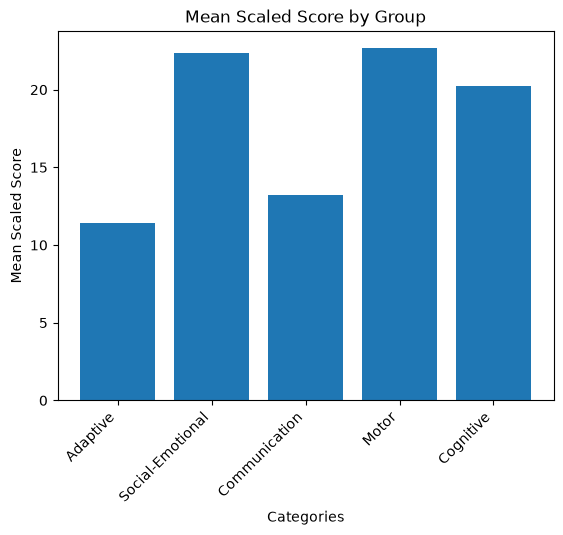

In [27]:
bars = ss_main.index
height = ss_main['Mean']
x_pos = range(len(bars))
plt.bar(x_pos, height)
plt.title('Mean Scaled Score by Group')
plt.xlabel('Categories')
plt.ylabel('Mean Scaled Score')
plt.xticks(x_pos, bars, rotation=45, ha='right')
plt.show()

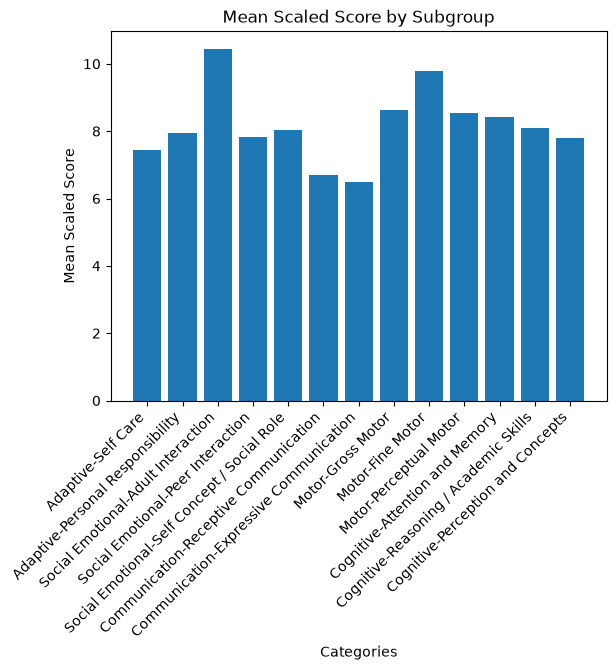

In [28]:
bars = ss_sub.index
height = ss_sub['Mean']
x_pos = range(len(bars))
plt.bar(x_pos, height)
plt.title('Mean Scaled Score by Subgroup')
plt.xlabel('Categories')
plt.ylabel('Mean Scaled Score')
plt.xticks(x_pos, bars, rotation=45, ha='right')
plt.show()